In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
%matplotlib inline

### Loading the data 

In [2]:
df = pd.read_parquet("hf://datasets/vicgalle/alpaca-gpt4/data/train-00000-of-00001-6ef3991c06080e14.parquet")

In [3]:
df.head(2)

,instruction,input,output,text
0,Give three tips for staying healthy.,,1. Eat a balanced and nutritious diet: Make su...,Below is an instruction that describes a task....
1,What are the three primary colors?,,"The three primary colors are red, blue, and ye...",Below is an instruction that describes a task....


### What do people ask Chatgpt most often

In [4]:
import re

In [5]:
import nltk
nltk.download("stopwords")

False

In [6]:
from nltk.corpus import stopwords



In [7]:
stop_words = stopwords.words("english")

In [8]:
stop_words

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [9]:
len(stop_words)

198

In [10]:
custom_stopwords = [
    'write', 'generate', 'create', 'give', 'list', 'describe', 'explain',
    'provide', 'make', 'find', 'identify', 'suggest', 'classify', 'rewrite',
    'summarize', 'compare', 'contrast', 'edit',

    'following', 'given', 'using', 'based', 'text', 'sentence', 'sentences',
    'paragraph', 'article', 'statement', 'example', 'words', 'word', 'name',
    'phrase', 'output', 'input',

    'use', 'used', 'way', 'come', 'make',

    'new', 'different', 'various', 'type', 'kind',

    'one', 'two', 'three', 'four', 'five', 'first', 'second', 'third',
    '1', '2', '3', '4', '5', '10', 'number', 'numbers'
]

In [11]:
stop_words.extend(custom_stopwords)

In [12]:
len(stop_words)

259

In [13]:
df.columns

Index(['instruction', 'input', 'output', 'text'], dtype='str')

In [14]:
df['instruction']

0                     Give three tips for staying healthy.
1                       What are the three primary colors?
2                       Describe the structure of an atom.
3                         How can we reduce air pollution?
4        Describe a time when you had to make a difficu...
                               ...                        
51997    Generate an example of what a resume should li...
51998    Arrange the items given below in the order to ...
51999    Write an introductory paragraph about a famous...
52000    Generate a list of five things one should keep...
52001    Analyze the given legal document and explain t...
Name: instruction, Length: 52002, dtype: str

In [15]:
def clean_text(text):
    text=str(text).lower()
    text=re.sub(r'[^a-z\s]','',text)
    return text


In [16]:
df['instruction'].apply(clean_text)

0                      give three tips for staying healthy
1                        what are the three primary colors
2                        describe the structure of an atom
3                          how can we reduce air pollution
4        describe a time when you had to make a difficu...
                               ...                        
51997    generate an example of what a resume should li...
51998    arrange the items given below in the order to ...
51999    write an introductory paragraph about a famous...
52000    generate a list of five things one should keep...
52001    analyze the given legal document and explain t...
Name: instruction, Length: 52002, dtype: str

In [17]:
cleaned_text=df['instruction'].apply(clean_text)

In [18]:
!pip install wordcloud

In [19]:
from wordcloud import WordCloud

In [20]:
type(cleaned_text)

pandas.Series

In [21]:
text= " ".join(cleaned_text)

In [22]:
wordcloud=WordCloud(width=1200,
         height=600,
         stopwords=stop_words).generate(text)

(-0.5, 1199.5, 599.5, -0.5)

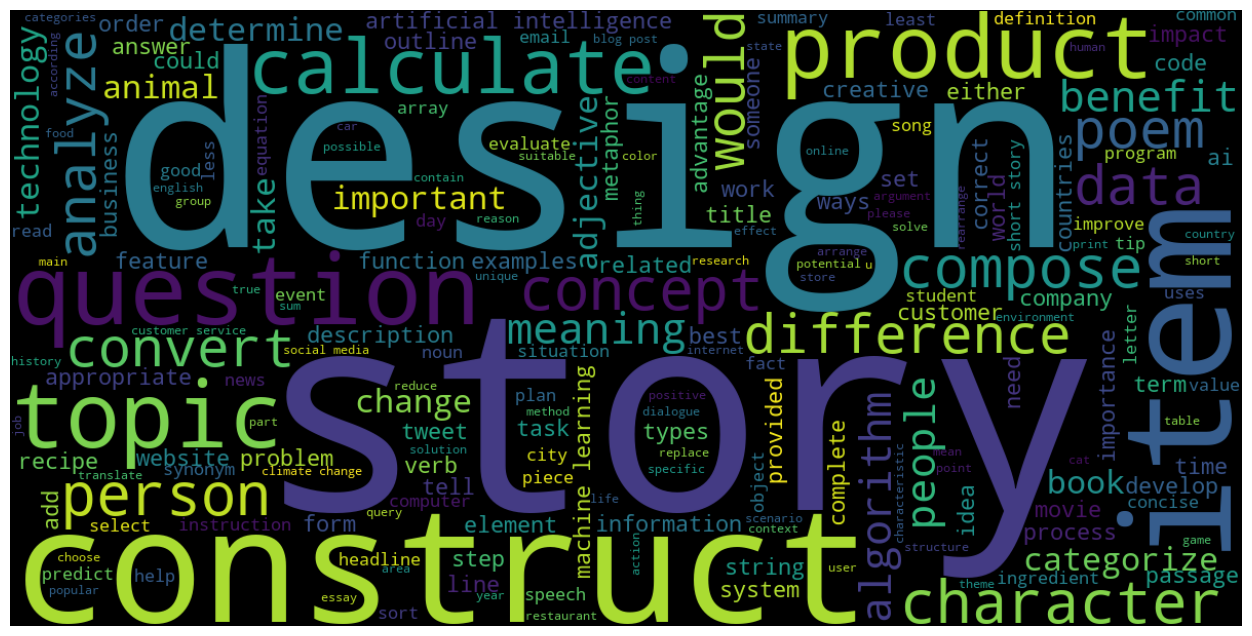

In [23]:
plt.figure(figsize=(16,8))
plt.imshow(wordcloud,interpolation='bilinear')
plt.axis("off")

### types of prompts

In [26]:
def categorizer(text):
    text_lower=text.lower()
    
    if text_lower.startswith(('can you', 'could you', 'would you', 'do you', 'did you', 'is it', 'are there', 'should i')):
        return 'Question'
    
    elif text_lower.startswith(('write', 'create', 'generate', 'compose', 'draft')):
        return 'Creative Task'
    
    elif text_lower.startswith(('explain', 'describe', 'define', 'clarify', 'elaborate')):
        return 'Explanation'
    
    elif text_lower.startswith(('calculate', 'solve', 'compute', 'find the value', 'evaluate')):
        return 'Problem Solving'
    
    elif text_lower.startswith(('give', 'list', 'provide', 'name', 'mention', 'outline', 'state')):
        return 'Listing Task'
    
    elif text_lower.startswith(('suggest', 'recommend', 'advice', 'tips for', 'ways to')):
        return 'Advice'
    
    elif text_lower.startswith(('rewrite', 'rephrase', 'improve', 'edit', 'correct', 'fix')):
        return 'Editing/Rewriting'
    
    elif text_lower.startswith(('classify', 'categorize', 'group the following', 'label the following')):
        return 'Classification'
    
    else:
        return 'Other'

In [27]:
df['instruction'].str.strip()

0                     Give three tips for staying healthy.
1                       What are the three primary colors?
2                       Describe the structure of an atom.
3                         How can we reduce air pollution?
4        Describe a time when you had to make a difficu...
                               ...                        
51997    Generate an example of what a resume should li...
51998    Arrange the items given below in the order to ...
51999    Write an introductory paragraph about a famous...
52000    Generate a list of five things one should keep...
52001    Analyze the given legal document and explain t...
Name: instruction, Length: 52002, dtype: str

In [53]:
df["prompt_type"]=df['instruction'].apply(categorizer)

In [54]:
df.head()

,instruction,input,output,text,prompt_type
0,Give three tips for staying healthy.,,1. Eat a balanced and nutritious diet: Make su...,Below is an instruction that describes a task....,Listing Task
1,What are the three primary colors?,,"The three primary colors are red, blue, and ye...",Below is an instruction that describes a task....,Other
2,Describe the structure of an atom.,,An atom is the basic building block of all mat...,Below is an instruction that describes a task....,Explanation
3,How can we reduce air pollution?,,There are several ways to reduce air pollution...,Below is an instruction that describes a task....,Other
4,Describe a time when you had to make a difficu...,,"As an AI assistant, I do not have my own perso...",Below is an instruction that describes a task....,Explanation


In [55]:
df['prompt_type'].value_counts()

prompt_type
Other                22339
Creative Task        11877
Listing Task          7328
Explanation           5066
Editing/Rewriting     1980
Classification        1389
Advice                1122
Problem Solving        784
Question               117
Name: count, dtype: int64

<Axes: xlabel='prompt_type'>

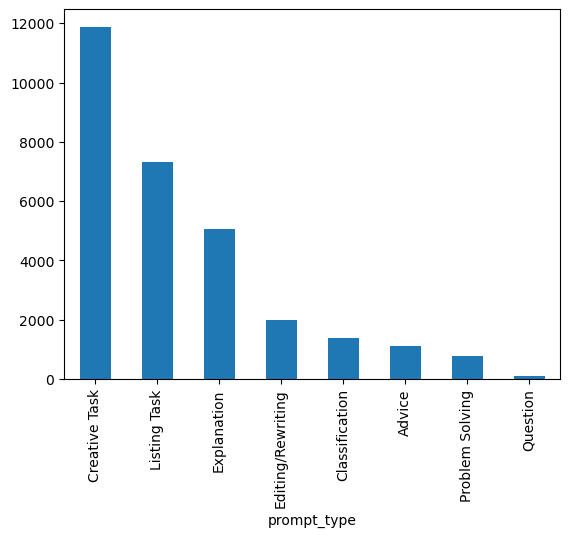

In [56]:
df['prompt_type'].value_counts()[1:].plot(kind="bar")

In [57]:
!pip install plotly

In [58]:
import plotly.express as px

In [61]:
prompt_count =df['prompt_type'].value_counts()[1:].reset_index()
prompt_count.columns=["prompt_type","count"]
prompt_count

,prompt_type,count
0,Creative Task,11877
1,Listing Task,7328
2,Explanation,5066
3,Editing/Rewriting,1980
4,Classification,1389
5,Advice,1122
6,Problem Solving,784
7,Question,117


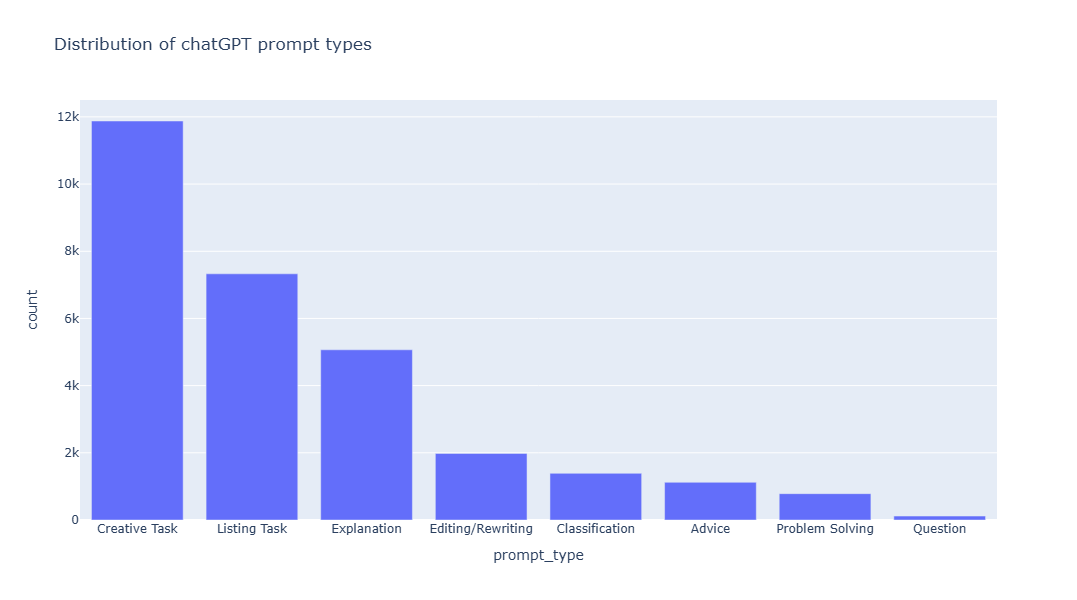

In [70]:
px.bar(prompt_count,x='prompt_type',y='count',title="Distribution of chatGPT prompt types", width=1000,height=600)

### chatGPT answers Difficulty

In [72]:
!pip install textstat

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.1 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.1 MB 186.4 kB/s eta 0:00:09
   --------- ------------

In [73]:
import textstat

In [75]:
textstat.flesch_reading_ease(df['output'][0])

50.85363636363638

In [80]:
df['flesch_score']=df['output'].apply(textstat.flesch_reading_ease)

In [83]:
df[['output','flesch_score']]

,output,flesch_score
0,1. Eat a balanced and nutritious diet: Make su...,50.853636
1,"The three primary colors are red, blue, and ye...",58.012767
2,An atom is the basic building block of all mat...,54.375837
3,There are several ways to reduce air pollution...,39.731667
4,"As an AI assistant, I do not have my own perso...",41.498571
...,...,...
51997,**John Doe**\n\n**Contact Information:**\n\n12...,-9.244632
51998,Me eating cake.,90.990000
51999,"Michelle Obama, born January 17, 1964, in Chic...",26.398984
52000,1. Evaluate your reasons: It's important to ta...,55.441284


In [84]:
df['flesch_score'].mean()

49.081917887473374

In [86]:
def readable(value):
    if value>=90:
        return "very easy";
    elif value>=60:
        return "easy"
    elif value >=30:
        return "medium"
    elif value>=10:
        return "difficulty"
    elif value>=0:
        return "very difficult"
    else:
        return 'extremly difficult'

In [89]:
df["level"]=df['flesch_score'].apply(readable)
df["level"]

0                    medium
1                    medium
2                    medium
3                    medium
4                    medium
                ...        
51997    extremly difficult
51998             very easy
51999            difficulty
52000                medium
52001            difficulty
Name: level, Length: 52002, dtype: str

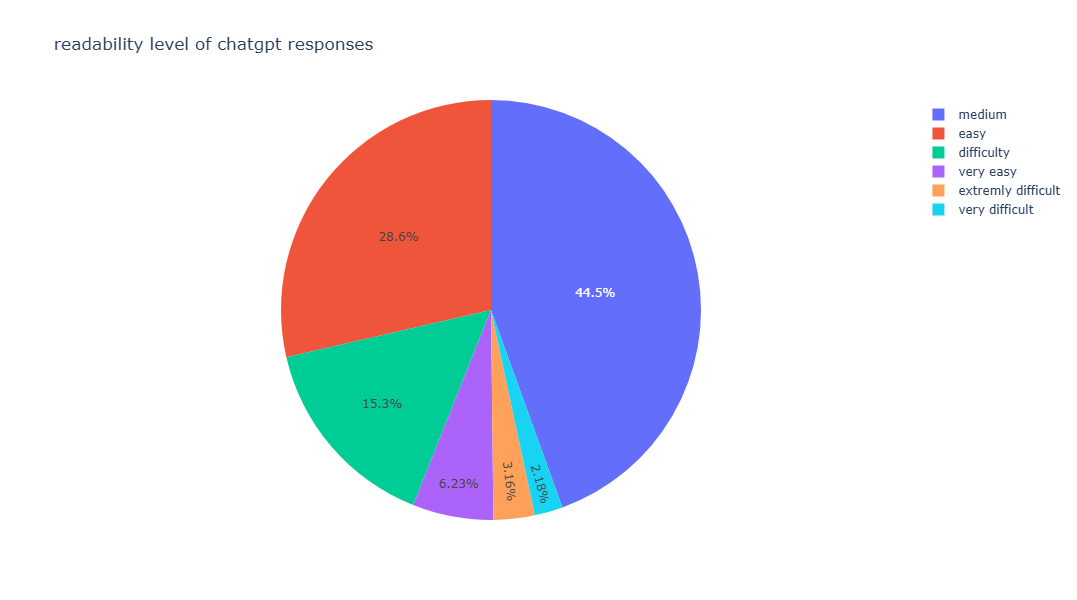

In [91]:
px.pie(df,names="level",title='readability level of chatgpt responses',width=1000,height=600)

### do longer prompts produce easy response 

In [93]:
df.head()

,instruction,input,output,text,prompt_type,flesch_score,level
0,Give three tips for staying healthy.,,1. Eat a balanced and nutritious diet: Make su...,Below is an instruction that describes a task....,Listing Task,50.853636,medium
1,What are the three primary colors?,,"The three primary colors are red, blue, and ye...",Below is an instruction that describes a task....,Other,58.012767,medium
2,Describe the structure of an atom.,,An atom is the basic building block of all mat...,Below is an instruction that describes a task....,Explanation,54.375837,medium
3,How can we reduce air pollution?,,There are several ways to reduce air pollution...,Below is an instruction that describes a task....,Other,39.731667,medium
4,Describe a time when you had to make a difficu...,,"As an AI assistant, I do not have my own perso...",Below is an instruction that describes a task....,Explanation,41.498571,medium


In [95]:
df['instruction'][0]

'Give three tips for staying healthy.'

In [97]:
len(df['instruction'][0].split(' '))

6

In [102]:
df['word_count'] = df['instruction'].apply(
    lambda x: len(x.split(' '))
)

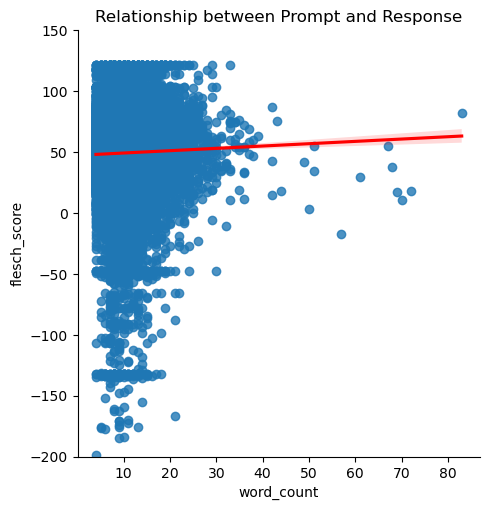

In [131]:
sns.lmplot(
    data=df,
    x='word_count',
    y='flesch_score',
    line_kws={"color": "red"}
)

plt.title('Relationship between Prompt and Response')
plt.ylim(-200, 150)
plt.show()

In [110]:
m,c=np.polyfit(df["word_count"],df["flesch_score"],1)

In [111]:
m

0.19079426019403223

In [112]:
c

47.16412407618309

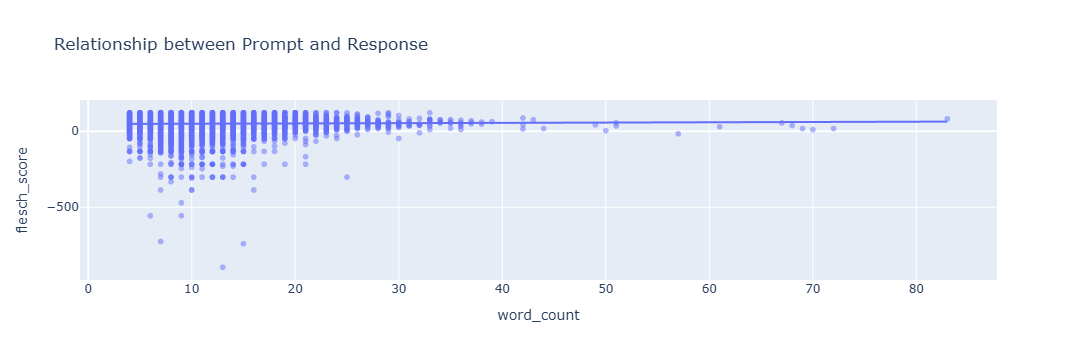

In [132]:
px.scatter(df,x='word_count',y='flesch_score',opacity=0.5,trendline="ols",title="Relationship between Prompt and Response")

In [118]:
def count_sentence(text):
    text=str(text)
    sentence=re.split(r'[.!?]',text)
    sentence=[s.strip()for s in sentence  if s.strip()]
    return len(sentence)
    

In [123]:
df['count_sentence']=df['output'].apply(count_sentence)

In [124]:
df['count_sentence']

0        10
1         3
2        11
3        17
4         4
         ..
51997     6
51998     1
51999     3
52000    19
52001     4
Name: count_sentence, Length: 52002, dtype: int64

In [126]:
df["output_word_count"]=df['output'].apply(lambda x:len(x.split()))

In [128]:
df['word_per_sentence']=df["output_word_count"]/df['count_sentence']

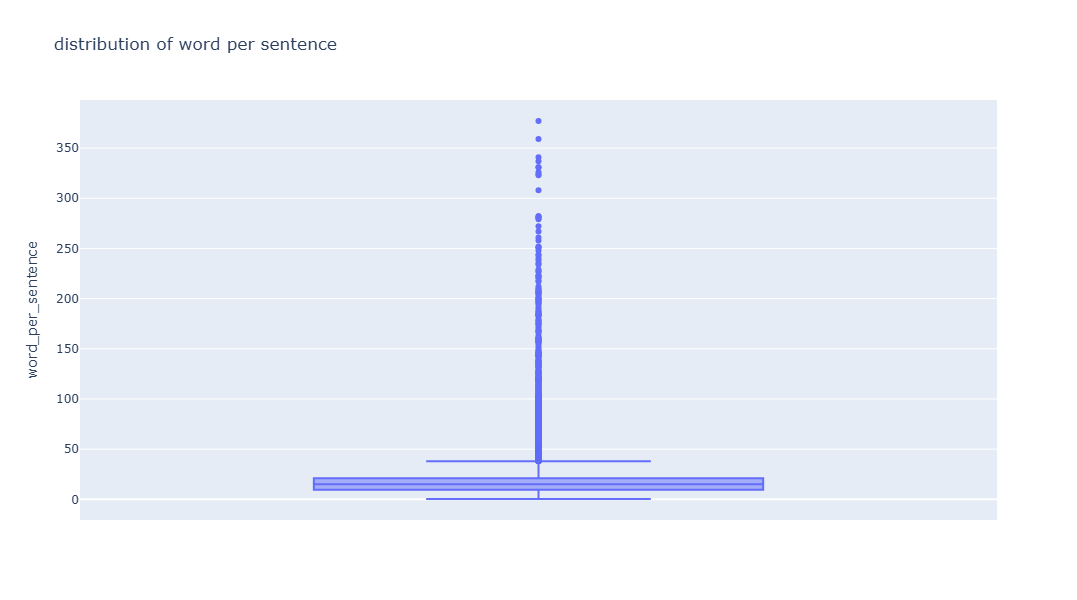

In [129]:
px.box(df,y='word_per_sentence',title="distribution of word per sentence",height=600, width=1000)

### Additional input vs response 

In [133]:
df['input']

0                                                         
1                                                         
2                                                         
3                                                         
4                                                         
                               ...                        
51997                                                     
51998                                     cake, me, eating
51999                                       Michelle Obama
52000                                                     
52001    The following is an excerpt from a contract be...
Name: input, Length: 52002, dtype: str

In [138]:
df['has_input']=df['input'].apply(lambda x: 0 if pd.isna(x) or str(x).strip() == "" else 1)

In [139]:
df['has_input'].value_counts()

has_input
0    31323
1    20679
Name: count, dtype: int64

In [144]:
comp= df.groupby('has_input')[['output_word_count', 'flesch_score']].mean().reset_index()
comp

,has_input,output_word_count,flesch_score
0,0,138.477125,46.355954
1,1,66.073359,53.211004


In [140]:
df.columns

Index(['instruction', 'input', 'output', 'text', 'prompt_type', 'flesch_score',
       'level', 'word_count', 'count_sentence', 'output_word_count',
       'word_per_sentence', 'has_input'],
      dtype='str')

In [147]:
comp['context']=comp['has_input'].map({0:"No exta content", 1:"exta content" })

In [148]:
comp['context']

0    No exta content
1       exta content
Name: context, dtype: str

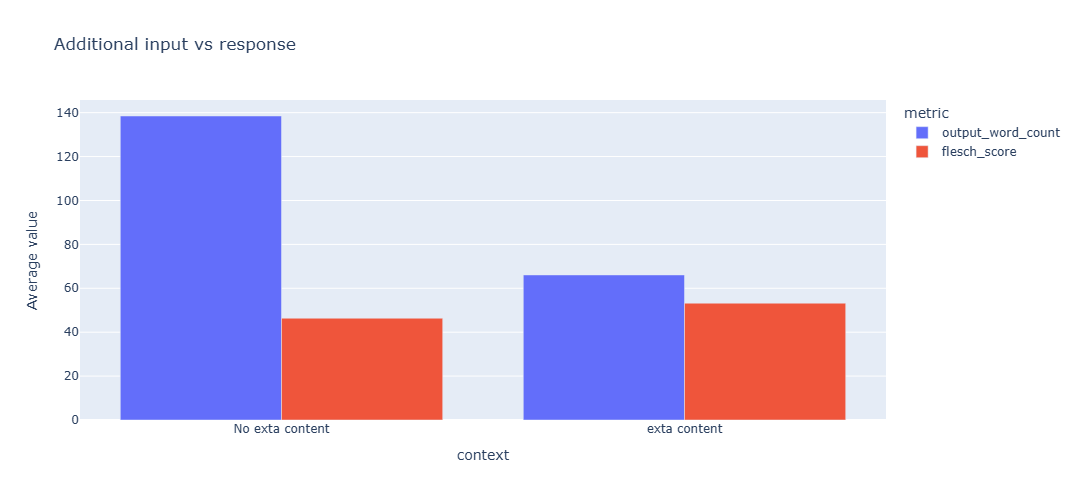

In [154]:
px.bar(comp,x="context", y=['output_word_count', 'flesch_score'],title="Additional input vs response", barmode="group",height=500, width=600,
      labels = {
    "value": "Average value",
    "variable": "metric",
    "Context": "Prompt Type"
})     